# 01 · Exploratory data analysis (Unit 1)

**Question:** using only what is known before an Indian mainboard IPO lists, can we predict its
listing-day gain (open price vs issue price) and whether it lists at a profit?

This notebook looks at why this tabular dataset is hard: skewed subscription multiples, outliers,
missing values, sector imbalance and regime shifts (the 2021 IPO boom). It ends by setting up the
question the project answers: **classical ML or deep learning on a small tabular dataset?**

Data: `data/processed/ipo_mainboard.csv`, built by `src/data.py` from public Chittorgarh pages
(issue terms, final-day subscription, listing-day prices) and yfinance (Nifty 50, India VIX).

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src import features as F
from src.data import FEATURES

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
FIG = Path("docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
OUT = Path("frontend/public/insights"); OUT.mkdir(parents=True, exist_ok=True)

df = F.load()
train, val, test = F.splits(df)
print(f"{len(df)} mainboard IPOs, listed {df.listing_date.min():%d %b %Y} to {df.listing_date.max():%d %b %Y}")
print(df["split"].value_counts().reindex(["train", "val", "test"]).to_string())

604 mainboard IPOs, listed 09 Mar 2012 to 08 Oct 2026
split
train    256
val       58
test     290


## 1. How many IPOs per year, and how did they list?
The time split is **train = listed up to 2022, validation = 2023, test = 2024 onward**. Never random:
a random split would let the model learn from 2025 IPOs to predict 2021 ones.

In [2]:
by_year = df.groupby("listing_year").agg(
    ipos=("ipo_id", "size"),
    median_gain=("listing_gain_pct", "median"),
    mean_gain=("listing_gain_pct", "mean"),
    pct_positive=("listed_positive", "mean"),
    median_total_x=("total_x", "median"),
).round(2)
by_year["pct_positive"] = (by_year["pct_positive"] * 100).round(1)
by_year

,ipos,median_gain,mean_gain,pct_positive,median_total_x
listing_year,,,,,
2012,11,1.48,5.61,64.0,2.54
2013,3,1.90,2.07,67.0,1.65
2014,5,28.00,30.56,80.0,38.06
2015,20,1.19,7.35,50.0,2.22
2016,27,9.59,12.29,74.0,11.07
2017,36,5.95,22.42,61.0,8.24
2018,24,1.35,5.18,50.0,5.14
2019,15,8.86,17.52,67.0,5.83
2020,14,35.81,43.23,71.0,60.68


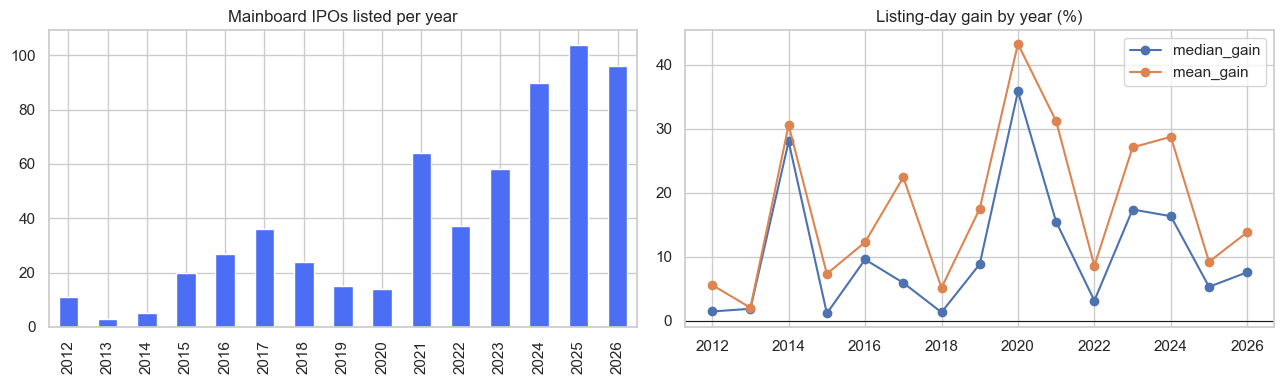

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
by_year["ipos"].plot.bar(ax=ax[0], color="#4C6EF5")
ax[0].set_title("Mainboard IPOs listed per year"); ax[0].set_xlabel("")
by_year[["median_gain", "mean_gain"]].plot(ax=ax[1], marker="o")
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_title("Listing-day gain by year (%)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_by_year.png", dpi=120); plt.show()

## 2. The target: skewed, fat-tailed, and a mean that misleads

mean 18.6%  median 8.2%  std 31.9  skew 2.28  kurtosis 7.93
listed above issue price: 69.2%   exactly flat: 7.1%


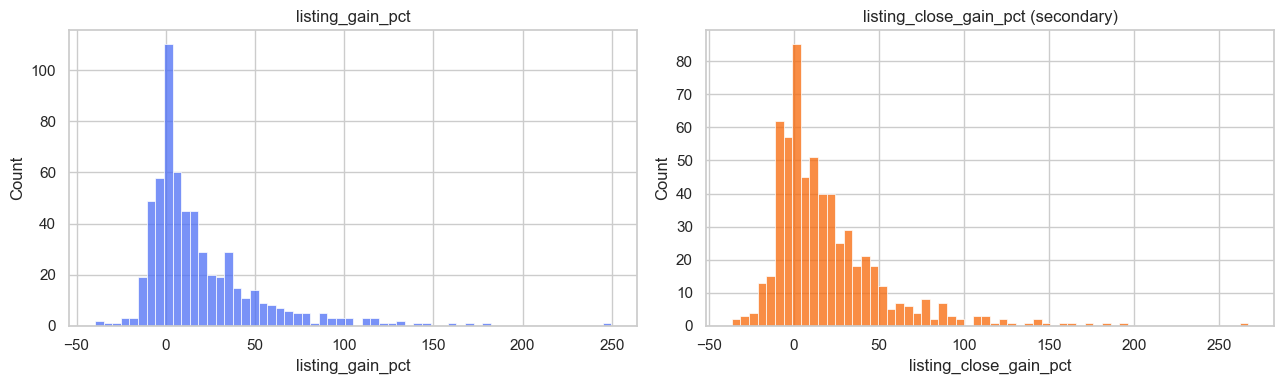

In [4]:
y = df["listing_gain_pct"]
print(f"mean {y.mean():.1f}%  median {y.median():.1f}%  std {y.std():.1f}  skew {stats.skew(y):.2f}  kurtosis {stats.kurtosis(y):.2f}")
print(f"listed above issue price: {df.listed_positive.mean()*100:.1f}%   exactly flat: {(y==0).mean()*100:.1f}%")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y, bins=60, ax=ax[0], color="#4C6EF5"); ax[0].set_title("listing_gain_pct")
sns.histplot(df["listing_close_gain_pct"], bins=60, ax=ax[1], color="#F76707"); ax[1].set_title("listing_close_gain_pct (secondary)")
plt.tight_layout(); plt.savefig(FIG / "eda_target.png", dpi=120); plt.show()

## 3. Subscription multiples are extremely skewed → log transform

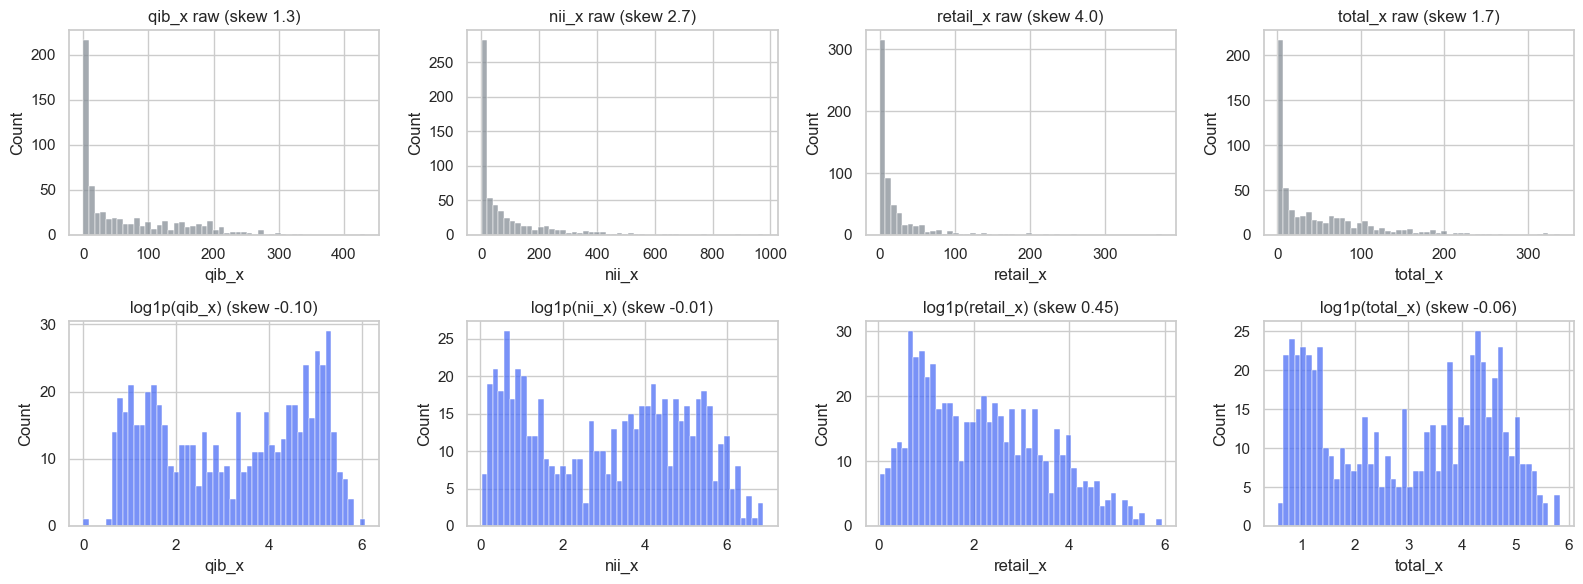

In [5]:
subs = ["qib_x", "nii_x", "retail_x", "total_x"]
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for i, c in enumerate(subs):
    s = df[c].dropna()
    sns.histplot(s, bins=50, ax=ax[0, i], color="#868E96"); ax[0, i].set_title(f"{c} raw (skew {stats.skew(s):.1f})")
    sns.histplot(np.log1p(s), bins=50, ax=ax[1, i], color="#4C6EF5"); ax[1, i].set_title(f"log1p({c}) (skew {stats.skew(np.log1p(s)):.2f})")
plt.tight_layout(); plt.savefig(FIG / "eda_subscription_log.png", dpi=120); plt.show()

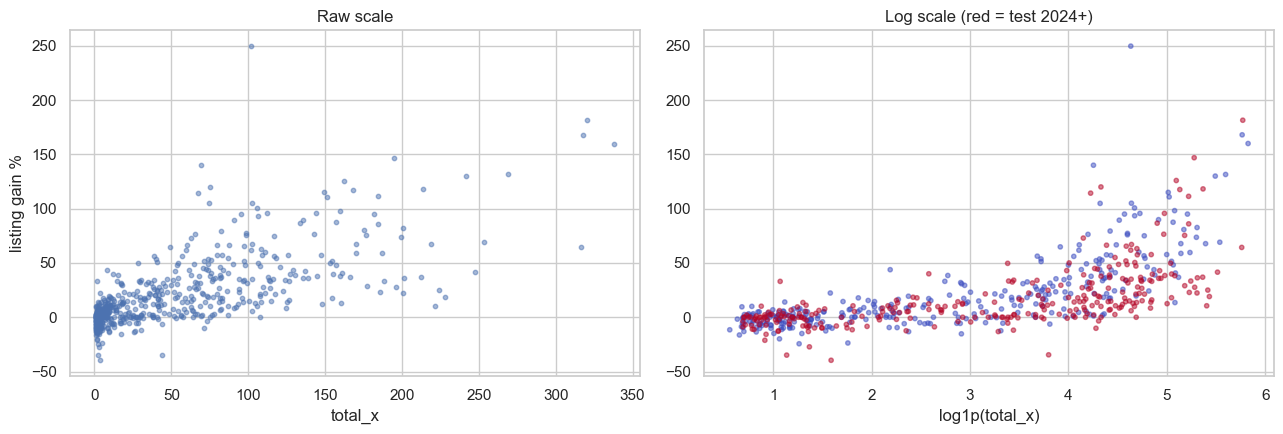

Spearman(total_x, gain) = 0.759


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(df["total_x"], y, s=10, alpha=0.5); ax[0].set_xlabel("total_x"); ax[0].set_ylabel("listing gain %"); ax[0].set_title("Raw scale")
ax[1].scatter(np.log1p(df["total_x"]), y, s=10, alpha=0.5, c=(df["split"] == "test"), cmap="coolwarm")
ax[1].set_xlabel("log1p(total_x)"); ax[1].set_title("Log scale (red = test 2024+)")
plt.tight_layout(); plt.savefig(FIG / "eda_total_x_vs_gain.png", dpi=120); plt.show()
print("Spearman(total_x, gain) =", round(stats.spearmanr(df.total_x, y, nan_policy="omit").statistic, 3))

## 4. Outliers

In [7]:
q1, q3 = y.quantile([0.25, 0.75]); iqr = q3 - q1
out = df[(y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)]
print(f"IQR outliers in the target: {len(out)} of {len(df)} ({len(out)/len(df)*100:.1f}%)")
cols = ["company", "listing_date", "issue_size_cr", "total_x", "listing_gain_pct"]
print("\nBiggest winners"); print(df.nlargest(8, "listing_gain_pct")[cols].to_string(index=False))
print("\nBiggest losers"); print(df.nsmallest(8, "listing_gain_pct")[cols].to_string(index=False))

IQR outliers in the target: 34 of 604 (5.6%)

Biggest winners
                                company listing_date  issue_size_cr  total_x  listing_gain_pct
                Sigachi Industries Ltd.   2021-11-15         125.43   101.91        249.693252
                Vibhor Steel Tubes Ltd.   2024-02-20          72.17   320.05        181.456954
Paras Defence & Space Technologies Ltd.   2021-10-01         170.78   318.04        168.000000
             Latent View Analytics Ltd.   2021-11-23         600.00   337.86        160.000000
                  Mamata Machinery Ltd.   2024-12-27         179.35   194.95        146.913580
                 Tata Technologies Ltd.   2023-11-30        3042.51    69.43        140.000000
        Salasar Techno Engineering Ltd.   2017-07-25          35.95   268.66        131.481481
         Astron Paper & Board Mill Ltd.   2017-12-29          69.83   241.76        130.000000

Biggest losers
                   company listing_date  issue_size_cr  total_x  li

Outliers are real IPOs (not data errors), so they are kept. Instead the regression models use a
**pseudo-Huber loss** that is less dominated by a handful of 100%+ listings, and we report MAE next to RMSE.

## 5. Missing values

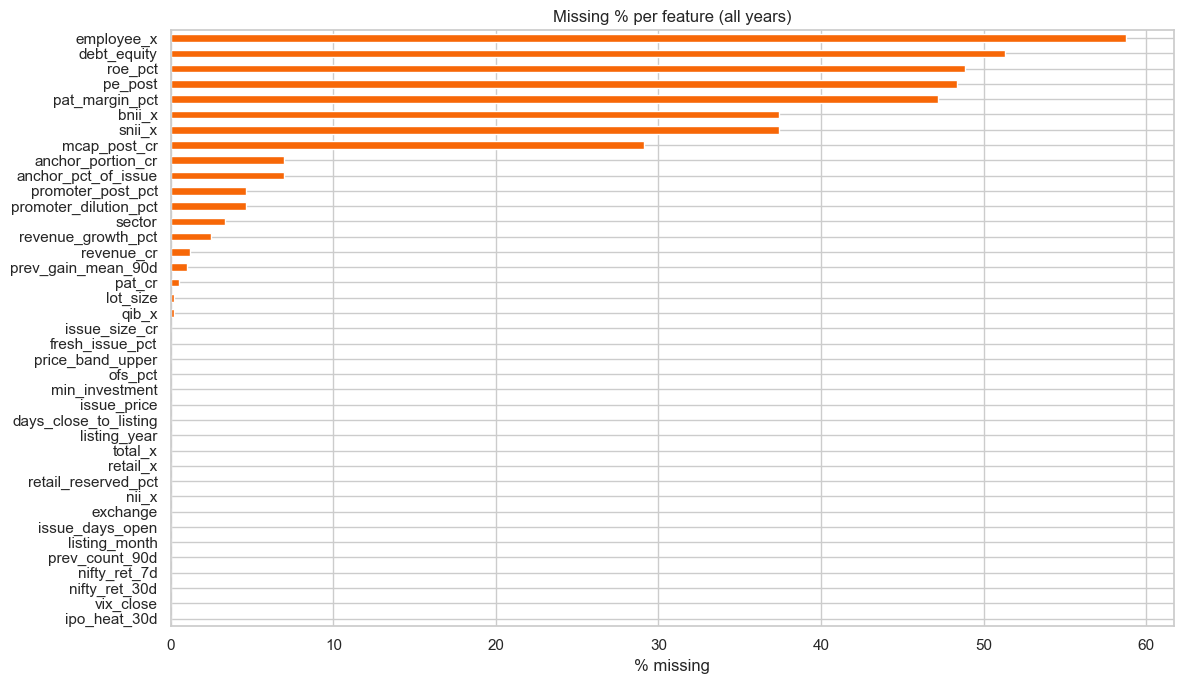

In [8]:
feat_cols = list(FEATURES)
miss = (df[feat_cols].isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 7))
miss.plot.barh(ax=ax, color="#F76707"); ax.invert_yaxis(); ax.set_xlabel("% missing")
ax.set_title("Missing % per feature (all years)")
plt.tight_layout(); plt.savefig(FIG / "eda_missing.png", dpi=120); plt.show()

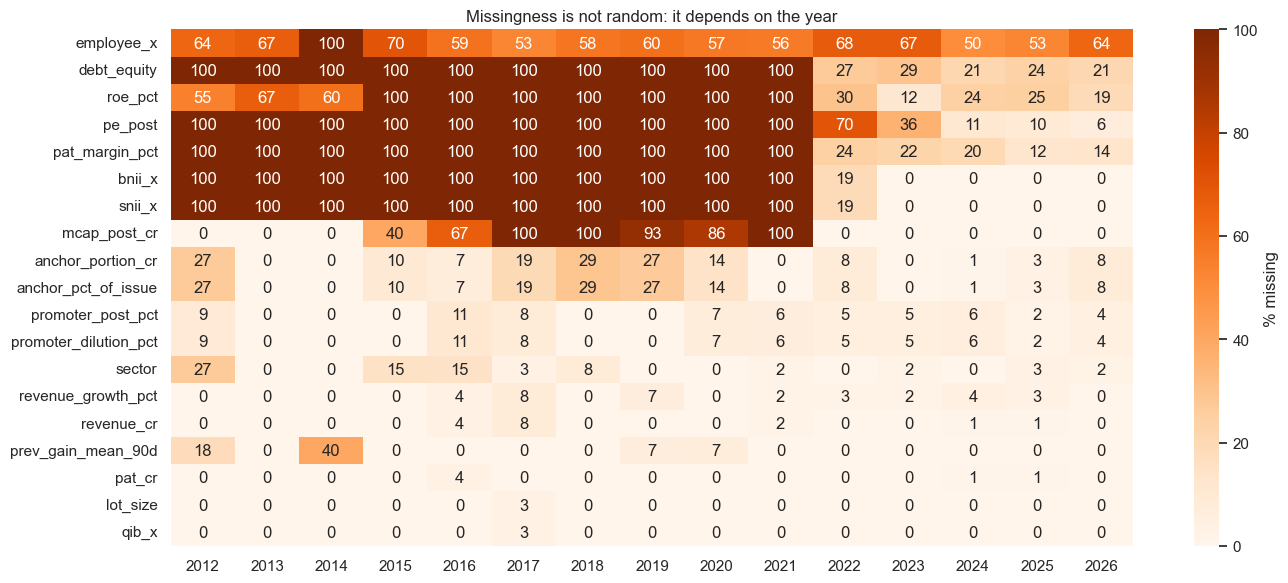

In [9]:
heat = df.groupby("listing_year")[miss[miss > 0].index.tolist()].apply(lambda g: g.isna().mean() * 100)
plt.figure(figsize=(14, 6))
sns.heatmap(heat.T, cmap="Oranges", annot=True, fmt=".0f", cbar_kws={"label": "% missing"})
plt.title("Missingness is not random: it depends on the year"); plt.xlabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_missing_by_year.png", dpi=120); plt.show()

## 6. Sector imbalance

In [10]:
sec = df["sector"].fillna("Unknown").value_counts()
print(sec.to_string())
sec_gain = df.assign(sector=df.sector.fillna("Unknown")).groupby("sector")["listing_gain_pct"].agg(["size", "median", "mean"]).round(1)
sec_gain.sort_values("size", ascending=False)

sector
Industrials               129
Consumer Cyclical         111
Financial Services         77
Basic Materials            68
Healthcare                 61
Technology                 60
Consumer Defensive         30
Unknown                    20
Communication Services     17
Real Estate                16
Utilities                  10
Energy                      5


,size,median,mean
sector,,,
Industrials,129,10.5,23.0
Consumer Cyclical,111,7.7,15.5
Financial Services,77,4.9,12.2
Basic Materials,68,14.9,26.8
Healthcare,61,10.0,18.5
Technology,60,7.0,27.9
Consumer Defensive,30,9.7,15.6
Unknown,20,0.0,3.7
Communication Services,17,5.9,15.7


## 7. Regime shifts: is 2024+ drawn from the same distribution as 2012–2022?
Kolmogorov–Smirnov test per feature, train vs test. A small p-value means the feature's
distribution moved, which is exactly the kind of drift a time split exposes and a random split hides.

In [11]:
rows = []
for c in feat_cols:
    a, b = pd.to_numeric(train[c], errors="coerce").dropna(), pd.to_numeric(test[c], errors="coerce").dropna()
    if len(a) > 10 and len(b) > 10:
        ks = stats.ks_2samp(a, b)
        rows.append({"feature": c, "train_median": a.median(), "test_median": b.median(), "KS": ks.statistic, "p": ks.pvalue})
drift = pd.DataFrame(rows).sort_values("KS", ascending=False).round(3)
drift.head(15)

,feature,train_median,test_median,KS,p
17,listing_year,2019.000,2025.000,1.000,0.0
20,days_close_to_listing,10.000,5.000,0.990,0.0
26,prev_count_90d,7.000,25.000,0.754,0.0
24,ipo_heat_30d,2.000,10.000,0.604,0.0
15,employee_x,1.310,5.730,0.475,0.0
23,vix_close,15.790,12.665,0.466,0.0
12,bnii_x,1.680,44.730,0.453,0.0
13,snii_x,1.030,31.495,0.447,0.0
6,min_investment,14670.000,14868.000,0.346,0.0
1,fresh_issue_pct,33.160,68.665,0.268,0.0


**What the drift table says.**
* `listing_year` drifts completely, by construction. That is why it is **not** a model feature: tree
  models cannot extrapolate, so 2024+ would just be treated as "the latest year seen in training".
* `days_close_to_listing` has KS ≈ 0.99. SEBI moved listing from T+6 to **T+3** in December 2023, so
  training IPOs list ~10 days after close and test IPOs ~3–5 days after. It encodes the era, not
  demand, so it is dropped from the model for the same reason as `listing_year`.
* `ipo_heat_30d` and `prev_count_90d` show that 2024–26 had far more IPOs per month than 2012–22.
  These are genuine "hot market" signals, so they stay, but the test years sit at the top of their
  training range.
* Subscription levels (QIB, retail, bNII/sNII) are much higher in 2024+: the test period is a hotter,
  more retail-heavy market than most of the training period.

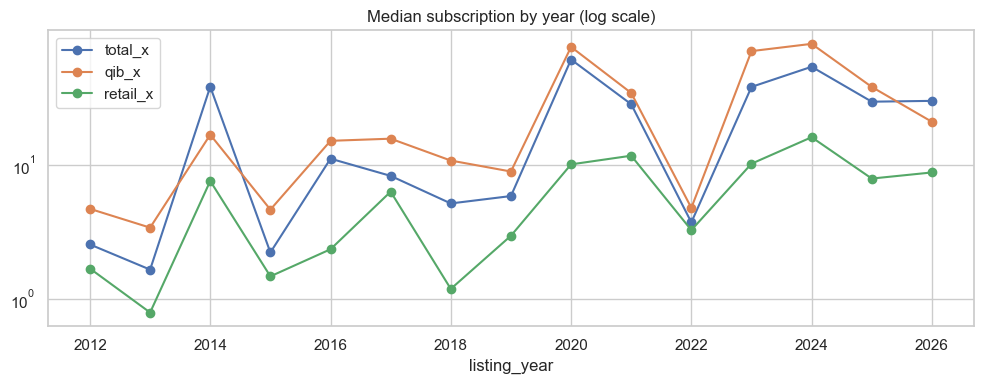

In [12]:
boom = df.groupby("listing_year")[["total_x", "qib_x", "retail_x"]].median()
boom.plot(marker="o", figsize=(10, 4), logy=True, title="Median subscription by year (log scale)")
plt.tight_layout(); plt.savefig(FIG / "eda_subscription_by_year.png", dpi=120); plt.show()

## 8. Which single features move with the target?

In [13]:
corr = []
for c in feat_cols:
    s = pd.to_numeric(df[c], errors="coerce")
    if s.notna().sum() > 30:
        r = stats.spearmanr(s, y, nan_policy="omit").statistic
        corr.append({"feature": c, "spearman_with_gain": r, "n": int(s.notna().sum())})
corr = pd.DataFrame(corr).sort_values("spearman_with_gain", key=abs, ascending=False).round(3)
corr.head(15)

,feature,spearman_with_gain,n
16,total_x,0.759,604
10,qib_x,0.726,603
11,nii_x,0.700,604
12,bnii_x,0.632,378
13,snii_x,0.611,378
14,retail_x,0.595,604
15,employee_x,0.360,249
31,roe_pct,0.246,309
22,nifty_ret_30d,0.180,604
34,mcap_post_cr,0.159,428


**Reading the correlations.** Subscription multiples dominate: total (ρ ≈ 0.76), QIB (≈ 0.73) and NII
(≈ 0.70) move with the listing gain far more than anything else. Company fundamentals (ROE, margins,
P/E) and market returns are weak on their own (|ρ| < 0.25). Since demand is only known at issue close,
that is the moment this model can be useful, not earlier.

## Summary of the EDA
* 604 mainboard IPOs, 2012 → Oct 2026. **69 %** listed above the issue price; **7 %** opened exactly flat.
* The target is right-skewed (median 8.2 %, mean 18.6 %, skew 2.3) with real outliers up to +250 %.
  They are kept; models use a Huber-type loss and we report MAE alongside RMSE.
* Subscription multiples span 0.1× to 300×+ and need a log transform for linear and neural models.
* Missingness is structural: bNII/sNII only exist after the 2022 NII split; P/E is missing for about
  half the issues, mostly older pages.
* Strong regime shifts: 2020–21 and 2023–24 were hot, 2015, 2018 and 2022 were cold, and the listing
  timeline itself changed (T+3).

## 9. Setting up the Unit 3 question: classical ML or deep learning?

Facts from this notebook that matter for that choice:
* the dataset is **small** (hundreds of rows, not hundreds of thousands),
* features are **heterogeneous** (multiples, rupee sizes, percentages, dates, categories) with very
  different scales and heavy tails,
* missingness is **structured** (whole blocks missing for older years),
* the target is **noisy and fat-tailed**, and the data distribution **drifts** between train and test.

Gradient-boosted trees are invariant to monotone transforms, handle missing values natively and
need little data; neural nets need normalisation, imputation and much more data to shine.
Notebooks 02 and 03 test this directly on the same time-based splits.

In [14]:
export = {
    "n_ipos": int(len(df)),
    "period": [f"{df.listing_date.min():%Y-%m-%d}", f"{df.listing_date.max():%Y-%m-%d}"],
    "splits": {k: int(v) for k, v in df["split"].value_counts().items()},
    "by_year": [{"year": int(i), **{k: (None if pd.isna(v) else float(v)) for k, v in r.items()}} for i, r in by_year.iterrows()],
    "gain_hist": [{"bin": float(b), "count": int(c)} for b, c in zip(*np.histogram(y.clip(-50, 150), bins=np.arange(-50, 155, 5))[::-1])],
    "scatter_total_x": [
        {"log_total_x": round(float(np.log1p(a)), 3), "gain": round(float(b), 2), "split": s, "company": n}
        for a, b, s, n in df[["total_x", "listing_gain_pct", "split", "company"]].dropna().itertuples(index=False)
    ],
    "missing_pct": [{"feature": k, "pct": round(float(v), 1)} for k, v in miss.items()],
    "sectors": [{"sector": k, "count": int(r["size"]), "median_gain": float(r["median"])} for k, r in sec_gain.iterrows()],
    "top_spearman": corr.head(12).to_dict(orient="records"),
}
(OUT / "eda.json").write_text(json.dumps(export, default=float))
print("wrote", OUT / "eda.json")

wrote frontend\public\insights\eda.json
